<a href="https://colab.research.google.com/github/brittanybee-alt/Capstone-Project-Three/blob/main/Capstone_Three_Data_Wrangling_%5BBrittany_Barrion%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Three, Step 2: Data Wrangling
## Investigating Fatigue-Related Aviation Safety Reports Through Statistical Analysis and Natural Language Processing

**Author:** Brittany Barrion | Springboard Data Science Career Track, Capstone Three

**Research question:** What statistical patterns and recurring narrative themes characterize fatigue-related aviation safety reports submitted to NASA's Aviation Safety Reporting System (ASRS) between 2009 and 2025?

**Data source:** NASA Aviation Safety Reporting System (ASRS) Database Online
- Database information: https://asrs.arc.nasa.gov/search/database.html
- Database search: https://asrsdbol.arc.nasa.gov/
- File: `ASRS_DBOnline.csv`, exported using fatigue-related search criteria

**What this notebook does.** It follows the four wrangling stages of the Data Science Method:

| Section | DSM stage | What happens |
|---|---|---|
| 1 | Data Collection | Load the raw ASRS export and handle its two header rows |
| 2 | Data Organization | Set up the project folder structure |
| 3 | Data Definition | Build a data dictionary and select the columns the research question needs |
| 4 | Data Cleaning | Duplicates, dates, the fatigue inclusion check, category clean-up, multi-value fields, missing values, outliers |
| 5 | NLP text preparation | Tokenization, stop word removal, lemmatization vs. stemming, frequency analysis |
| 6 | Save outputs | Cleaned dataset, data dictionary, exclusion log |

Each decision is written up next to the code that carries it out, with the evidence behind it.

### 0. Setup
Libraries used: `pandas` and `numpy` for data handling, `matplotlib` and `seaborn` for plots, and `nltk` for text processing (stop words, lemmatization, stemming). Google Colab already has all of them installed. The `nltk.download` lines fetch the word lists NLTK needs.

In [6]:
import os
import re
import shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid")

## 1. Data Collection

**How the data was acquired.** I searched NASA's ASRS Database Online with fatigue-related criteria and exported the results as `ASRS_DBOnline.csv`. ASRS is a voluntary, confidential reporting system: pilots, air traffic controllers, maintenance technicians, flight attendants, dispatchers and others submit reports about safety incidents, and NASA analysts code each report into structured fields and de-identify the narrative.

**Getting the file into Colab.** The cell below looks for the file in `data/raw/`. If it isn't there and the notebook is running in Colab, it opens an upload box. Choose `ASRS_DBOnline.csv` from your computer.

In [7]:
RAW_DIR = "data/raw"
INTERIM_DIR = "data/interim"
PROCESSED_DIR = "data/processed"
FIG_DIR = "figures"
for folder in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)

RAW_FILE = os.path.join(RAW_DIR, "/content/ASRS_DBOnline.csv")

if not os.path.exists(RAW_FILE):
    try:
        from google.colab import files
        uploaded = files.upload()                    # pick ASRS_DBOnline.csv
        shutil.move(next(iter(uploaded)), RAW_FILE)
    except ImportError:
        raise FileNotFoundError(f"Place ASRS_DBOnline.csv in {RAW_DIR}/ and re-run this cell.")

print("Raw file:", RAW_FILE, "|", round(os.path.getsize(RAW_FILE) / 1e6, 1), "MB")

Raw file: /content/ASRS_DBOnline.csv | 2.1 MB


### 1.1 The export has two header rows
The ASRS export has **two header rows**. Row 1 is a *group* label (Time, Place, Aircraft 1, Person 1, Events, ...) and row 2 is the actual field name. Several field names repeat across groups. For example, `Flight Phase` appears under both *Aircraft 1* and *Aircraft 2*, and `Human Factors` under both *Person 1* and *Person 2*. If I read only row 2, pandas would silently rename the repeats to `Flight Phase.1`, and it would no longer be clear which aircraft or person a column belongs to.

**Decision:** read the data with `header=1` (the second row), then rebuild each column name as `"Group | Field"` so every name is unique and self-explanatory.

In [8]:
header_rows = pd.read_csv(RAW_FILE, header=None, nrows=2)
display(header_rows.iloc[:, :8])

,0,1,2,3,4,5,6,7
0,,Time,Time,Place,Place,Place,Place,Place
1,ACN,Date,Local Time Of Day,Locale Reference,State Reference,Relative Position.Angle.Radial,Relative Position.Distance.Nautical Miles,Altitude.AGL.Single Value


In [9]:
import csv

# We use quoting=csv.QUOTE_NONE (or 3) or escapechar to prevent unclosed quotes in narratives from breaking the parser
raw = pd.read_csv(RAW_FILE, header=1, low_memory=False, quoting=csv.QUOTE_NONE, sep=",")

groups = header_rows.iloc[0].fillna("").astype(str).str.strip()
fields = header_rows.iloc[1].fillna("").astype(str).str.strip()
raw.columns = [
    f"{g} | {f}" if g else (f if f else f"unnamed_{i}")
    for i, (g, f) in enumerate(zip(groups, fields))
]

# Remove trailing quotes that might remain from ignoring quotes during parsing if necessary
for col in raw.columns:
    if raw[col].dtype == object:
        raw[col] = raw[col].astype(str).str.strip('"')

assert raw.columns.is_unique, "Column names are still not unique"
print("Raw shape (rows, columns):", raw.shape)
print(raw.columns[:12].tolist())

Raw shape (rows, columns): (627, 126)
['ACN', 'Time | Date', 'Time | Local Time Of Day', 'Place | Locale Reference', 'Place | State Reference', 'Place | Relative Position.Angle.Radial', 'Place | Relative Position.Distance.Nautical Miles', 'Place | Altitude.AGL.Single Value', 'Place | Altitude.MSL.Single Value', 'Place | Latitude / Longitude (UAS)', 'Environment | Flight Conditions', 'Environment | Weather Elements / Visibility']


In [10]:
display(raw.head(3))

,ACN,Time | Date,Time | Local Time Of Day,Place | Locale Reference,Place | State Reference,Place | Relative Position.Angle.Radial,Place | Relative Position.Distance.Nautical Miles,Place | Altitude.AGL.Single Value,Place | Altitude.MSL.Single Value,Place | Latitude / Longitude (UAS),Environment | Flight Conditions,Environment | Weather Elements / Visibility,Environment | Work Environment Factor,Environment | Light,Environment | Ceiling,Environment | RVR.Single Value,Aircraft 1 | ATC / Advisory,Aircraft 1 | Aircraft Operator,Aircraft 1 | Make Model Name,Aircraft 1 | Aircraft Zone,Aircraft 1 | Crew Size,Aircraft 1 | Operating Under FAR Part,Aircraft 1 | Flight Plan,Aircraft 1 | Mission,Aircraft 1 | Nav In Use,Aircraft 1 | Flight Phase,Aircraft 1 | Route In Use,Aircraft 1 | Airspace,Aircraft 1 | Maintenance Status.Maintenance Deferred,Aircraft 1 | Maintenance Status.Records Complete,...,Person 1 | Cabin Activity,Person 1 | Human Factors,Person 1 | Communication Breakdown,Person 1 | UAS Communication Breakdown,Person 1 | ASRS Report Number.Accession Number,Person 2 | Location Of Person,Person 2 | Location In Aircraft,Person 2 | Reporter Organization,Person 2 | Function,Person 2 | Qualification,Person 2 | Experience,Person 2 | Cabin Activity,Person 2 | Human Factors,Person 2 | Communication Breakdown,Person 2 | UAS Communication Breakdown,Person 2 | ASRS Report Number.Accession Number,Events | Anomaly,Events | Miss Distance,Events | Were Passengers Involved In Event,Events | Detector,Events | When Detected,Events | Result,Assessments | Contributing Factors / Situations,Assessments | Primary Problem,Report 1 | Narrative,Report 1 | Callback,Report 2 | Narrative,Report 2 | Callback,Report 1 | Synopsis,unnamed_125
0,833953,200905,0601-1200,ZZZZ.Airport,FO,NaN,NaN,0.0,NaN,NaN,VMC,nan,nan,nan,nan,NaN,nan,Air Carrier,A320,NaN,2.0,Part 121,IFR,Passenger,nan,Parked,nan,nan,nan,nan,...,nan,Communication Breakdown; Fatigue; Time Pressure,Party1 Flight Crew; Party2 Dispatch; Party2 Ground Personnel; Party2 Maintenance,NaN,833953,Aircraft X,Flight Deck,Air Carrier,Pilot Not Flying; First Officer,nan,Flight Crew Last 90 Days 130; Flight Crew Total 13000; Flight Crew Type 130,nan,nan,nan,NaN,833958.0,Aircraft Equipment Problem Critical; Flight Deck / Cabin / Aircraft Event Other / Unknown; Infli...,nan,Y,Person Flight Crew,Pre-flight,General Maintenance Action; General Release Refused / Aircraft Not Accepted; General Flight Canc...,Company Policy; Human Factors; Procedure; Aircraft,Aircraft,Inbound aircraft cabin system pressure 1 inop. Maintenance history reveals chronic write-up. Cel...,nan,The station provided us no help whatsoever. I suggested that we clear through the Customs then g...,nan,A320 was not airworthy or repairable for departure at an international station and attempts by t...,NaN
1,834174,200904,0601-1200,ZZZ.Airport,US,NaN,NaN,0.0,NaN,NaN,nan,Clear; 10,nan,Daylight,15000,NaN,nan,Personal,Skyhawk 172/Cutlass 172,NaN,1.0,Part 91,VFR,Personal,nan,Landing,Visual Approach,nan,nan,nan,...,nan,Fatigue; Situational Awareness; Training / Qualification,nan,NaN,834174,nan,nan,nan,nan,nan,nan,nan,nan,nan,NaN,NaN,Inflight Event / Encounter Loss Of Aircraft Control; Inflight Event / Encounter Weather / Turbul...,nan,N,Person Flight Crew,In-flight,Aircraft Aircraft Damaged,Human Factors; Weather,Human Factors,I was on approach; landing on Runway 30. Weather was clear; calm winds; unlimited visibility. M...,nan,nan,nan,Low time pilot of a Cessna 172 lost control of his aircraft on landing.,NaN
2,834460,200904,0601-1200,ZZZ.Airport,US,NaN,0.0,0.0,NaN,NaN,VMC,10,nan,Daylight,nan,NaN,nan,Air Carrier,B727 Undifferentiated or Other Model,NaN,3.0,Part 121,IFR,Cargo / Freight / Delivery,nan,Taxi,nan,nan,nan,nan,...,nan,Communication Breakdown; Training / Qualification; Time Pressure; Situational Awareness; Fatigue,Party1 Flight Crew; Party2 Flight Crew,NaN,834460,nan,nan,nan,nan,nan,nan,nan,nan,nan,NaN,NaN,Deviation / Discrepancy - Procedural FAR; Devi

**Collection results.** The raw export has **2,246 reports and 126 columns**. The last column (`unnamed_125`) has no header and no values. It comes from a trailing comma at the end of each line in the export, and I remove it in the Data Definition section.

The raw DataFrame `raw` stays untouched for the rest of the notebook. All cleaning happens on a copy, so every step can be traced back to the original export.

## 2. Data Organization

The project uses a standard data-science folder layout so the GitHub repository is easy to navigate and the work can be reproduced:

```
capstone-three/
├── data/
│   ├── raw/          ← ASRS_DBOnline.csv exactly as downloaded (never edited)
│   ├── interim/      ← data dictionary, exclusion log, intermediate checks
│   └── processed/    ← cleaned dataset used for EDA and modeling
├── figures/          ← saved plots
├── notebooks/
│   ├── 01_Data_Wrangling.ipynb
│   └── 02_EDA.ipynb
└── README.md
```

The folders were created in the setup cell above. The check below confirms they exist.

In [11]:
for folder in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, FIG_DIR]:
    print(f"{folder:<16} exists: {os.path.isdir(folder)}")

data/raw         exists: True
data/interim     exists: True
data/processed   exists: True
figures          exists: True


## 3. Data Definition

### 3.1 Data dictionary for every raw column
For each column I record its group, data type, number of non-missing values, percent missing, number of unique values, percent unique, and an example value. Percent unique is calculated over the non-missing values only.

In [12]:
def build_data_dictionary(df):
    rows = []
    for col in df.columns:
        s = df[col]
        non_null = int(s.notna().sum())
        n_unique = int(s.nunique())
        rows.append({
            "column": col,
            "group": col.split(" | ")[0] if " | " in col else "",
            "dtype": str(s.dtype),
            "non_null": non_null,
            "pct_missing": round(100 * (1 - non_null / len(df)), 1),
            "n_unique": n_unique,
            "pct_unique": round(100 * n_unique / non_null, 1) if non_null else 0.0,
            "example": str(s.dropna().iloc[0])[:60] if non_null else "",
        })
    return pd.DataFrame(rows)

data_dict_raw = build_data_dictionary(raw)
data_dict_raw.to_csv(os.path.join(INTERIM_DIR, "data_dictionary_raw.csv"), index=False)
display(data_dict_raw)

,column,group,dtype,non_null,pct_missing,n_unique,pct_unique,example
0,ACN,,int64,627,0.0,627,100.0,833953
1,Time | Date,Time,int64,627,0.0,39,6.2,200905
2,Time | Local Time Of Day,Time,object,627,0.0,6,1.0,0601-1200
3,Place | Locale Reference,Place,object,627,0.0,129,20.6,ZZZZ.Airport
4,Place | State Reference,Place,object,627,0.0,40,6.4,FO
...,...,...,...,...,...,...,...,...
121,Report 1 | Callback,Report 1,object,627,0.0,30,4.8,nan
122,Report 2 | Narrative,Report 2,object,627,0.0,144,23.0,The station provided us no help whatsoever. I suggested that
123,Report 2 | Callback,Report 2,object,627,0.0,3,0.5,nan
124,Report 1 | Synopsis,Report 1,object,627,0.0,627,100.0,A320 was not airworthy or repairable for departure at an int


### 3.2 How complete is the data overall?

,number of columns
pct_missing,
0%,72
0-25%,1
25-50%,1
50-75%,2
75-95%,1
95-<100%,5
100% (empty),44


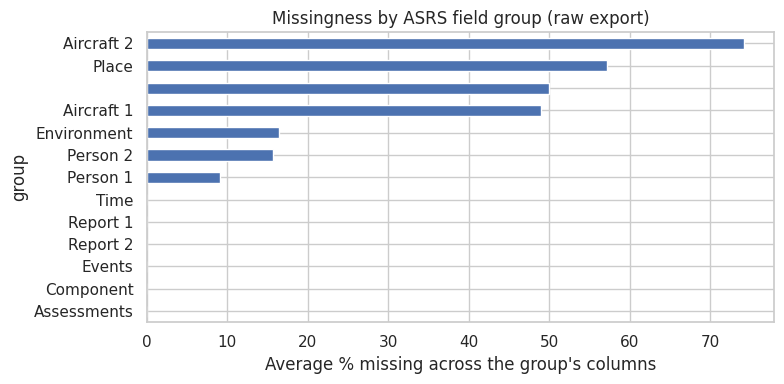

In [13]:
bins = [-0.1, 0, 25, 50, 75, 95, 99.99, 100]
labels = ["0%", "0-25%", "25-50%", "50-75%", "75-95%", "95-<100%", "100% (empty)"]
missing_bands = pd.cut(data_dict_raw["pct_missing"], bins=bins, labels=labels).value_counts().reindex(labels)
display(missing_bands.rename("number of columns").to_frame())

group_missing = data_dict_raw.groupby("group")["pct_missing"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
group_missing.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Average % missing across the group's columns")
ax.set_title("Missingness by ASRS field group (raw export)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "01_missing_by_group.png"), dpi=150)
plt.show()

**What this shows.** Missingness is very uneven. Many columns are almost entirely empty: the *Aircraft 2* fields are only filled in when a second aircraft was involved, the *UAS* fields apply only to drone reports, and the maintenance-status fields apply only to maintenance reports. In ASRS, a blank field usually means **"not applicable" or "not reported,"** not a data-entry error. That affects how I handle missing values later.

### 3.3 Fields holding several values at once
Many ASRS fields pack several values into one cell, separated by semicolons. For example, Human Factors might read `Fatigue; Workload; Time Pressure`. These need to be split into separate indicator columns before they can be counted or correlated.

In [14]:
def is_text_column(series):
    """True for text columns in both pandas 2 (object dtype) and pandas 3 (str dtype)."""
    return series.dtype == object or pd.api.types.is_string_dtype(series.dtype)

multi_valued = [c for c in raw.columns
                if is_text_column(raw[c]) and raw[c].notna().any()
                and raw[c].dropna().astype(str).str.contains(";").mean() > 0.05
                and "Narrative" not in c and "Synopsis" not in c and "Callback" not in c]
print("Columns where more than 5% of filled cells contain several ';'-separated values:")
for c in multi_valued:
    print("  -", c)

Columns where more than 5% of filled cells contain several ';'-separated values:
  - Environment | Weather Elements / Visibility
  - Aircraft 1 | Make Model Name
  - Aircraft 1 | Maintenance Status.Maintenance Items Involved
  - Person 1 | Function
  - Person 1 | Qualification
  - Person 1 | Experience
  - Person 1 | Human Factors
  - Person 1 | Communication Breakdown
  - Person 2 | Function
  - Person 2 | Qualification
  - Person 2 | Experience
  - Person 2 | Human Factors
  - Person 2 | Communication Breakdown
  - Events | Anomaly
  - Events | Detector
  - Events | Result
  - Assessments | Contributing Factors / Situations


Of these multi-value fields, the ones I keep are **Human Factors, Anomaly, Contributing Factors, Flight Phase, Function and Experience**. Section 4 shows how each one is split or parsed.

### 3.4 Column selection
I keep the columns that answer the research question and drop the rest, using three data-supported rules:

1. **Drop columns that are empty or nearly empty (≥ 95% missing).** They cannot support analysis.
2. **Drop columns outside the research question**, even when they are reasonably complete: *Aircraft 2* fields (a second aircraft appears in under 7% of reports), drone-specific (UAS) fields, maintenance-status details, and location or airspace codes that the ASRS de-identification process masks.
3. **Drop redundant identifiers.** `Person 1 | ASRS Report Number.Accession Number` duplicates `ACN`. The check below confirms it.

The kept columns cover the four parts of the research question: **when** (date, time of day, light), **what kind of operation** (operator, mission, FAR Part, crew size, flight phase), **who reported and what human factors were present** (reporter function, experience, human factors), **what happened** (anomaly, contributing factors, primary problem), and **the narratives** for NLP.

In [15]:
print("Accession number identical to ACN for every report:",
      (raw["ACN"] == raw["Person 1 | ASRS Report Number.Accession Number"]).all())

KEEP = {
    "ACN": "acn",
    "Time | Date": "date_raw",
    "Time | Local Time Of Day": "time_of_day",
    "Environment | Flight Conditions": "flight_conditions",
    "Environment | Light": "light",
    "Aircraft 1 | Aircraft Operator": "operator_raw",
    "Aircraft 1 | Make Model Name": "aircraft_model",
    "Aircraft 1 | Crew Size": "crew_size",
    "Aircraft 1 | Operating Under FAR Part": "far_part_raw",
    "Aircraft 1 | Flight Plan": "flight_plan",
    "Aircraft 1 | Mission": "mission_raw",
    "Aircraft 1 | Flight Phase": "flight_phase_raw",
    "Person 1 | Reporter Organization": "reporter_org",
    "Person 1 | Function": "reporter_function",
    "Person 1 | Experience": "reporter_experience",
    "Person 1 | Human Factors": "hf_person1",
    "Person 2 | Human Factors": "hf_person2",
    "Events | Anomaly": "anomaly_raw",
    "Assessments | Contributing Factors / Situations": "contrib_raw",
    "Assessments | Primary Problem": "primary_problem",
    "Report 1 | Narrative": "narrative_1",
    "Report 2 | Narrative": "narrative_2",
    "Report 1 | Synopsis": "synopsis",
    "Report 1 | Callback": "callback_1",
}

selection = data_dict_raw[["column", "pct_missing"]].copy()
selection["kept"] = selection["column"].isin(KEEP)
selection["reason"] = np.select(
    [selection["kept"],
     selection["pct_missing"] >= 95,
     selection["column"].str.startswith("Aircraft 2"),
     selection["column"].str.contains("UAS"),
     selection["column"].str.contains("Maintenance Status|Component"),
     selection["column"].str.contains("Accession")],
    ["kept: needed for the research question",
     "dropped: >= 95% missing",
     "dropped: second aircraft (rarely present, outside the question)",
     "dropped: drone-specific field",
     "dropped: maintenance/component detail outside the question",
     "dropped: duplicates ACN"],
    default="dropped: outside the research question / masked location detail",
)
selection.to_csv(os.path.join(INTERIM_DIR, "column_selection_log.csv"), index=False)
display(selection["reason"].value_counts().to_frame("number of columns"))

df = raw[list(KEEP)].rename(columns=KEEP).copy()
print("Working dataset shape:", df.shape)

Accession number identical to ACN for every report: True


,number of columns
reason,
dropped: >= 95% missing,49
dropped: outside the research question / masked location detail,32
kept: needed for the research question,24
dropped: maintenance/component detail outside the question,10
"dropped: second aircraft (rarely present, outside the question)",9
dropped: duplicates ACN,2


Working dataset shape: (627, 24)


## 4. Data Cleaning

### 4.1 Duplicates
Duplicates are checked at three levels:
- **Report ID (`acn`)**: every report should have exactly one row.
- **Entire rows**: exact copies.
- **Narratives and synopses**: the same story submitted twice under different IDs would give that story double weight in the NLP analysis.

In [16]:
print("Duplicate ACNs:          ", df["acn"].duplicated().sum())
print("Fully duplicated rows:   ", df.duplicated().sum())
print("Duplicate narratives:    ", df["narrative_1"].duplicated().sum())
print("Duplicate synopses:      ", df["synopsis"].duplicated().sum())

dup_syn = df[df["synopsis"].duplicated(keep=False)][["acn", "date_raw", "synopsis", "narrative_1"]]
display(dup_syn)
print("Do those two reports have the same narrative?",
      dup_syn["narrative_1"].nunique() == 1)

Duplicate ACNs:           0
Fully duplicated rows:    0
Duplicate narratives:     0
Duplicate synopses:       0


,acn,date_raw,synopsis,narrative_1


Do those two reports have the same narrative? False


**Decision: no rows removed.** There are no duplicate ACNs, no duplicated rows, and no duplicated primary narratives. One synopsis is shared by two reports (both drone/UAS reports), but their narratives are different, so they are two separate events that NASA analysts summarized with the same template sentence. Both are kept.

### 4.2 Parse the incident date and apply the 2009–2025 study window
`Date` is stored in YYYYMM format (e.g., `200905` = May 2009). ASRS reports only the month and year, never the exact day, as part of de-identification. I confirm every value has six digits, convert it to a real date, and pull out `year` and `month`.

All dates are 6 digits: True | Missing dates: 0
Date range: Aug 2006 to May 2012


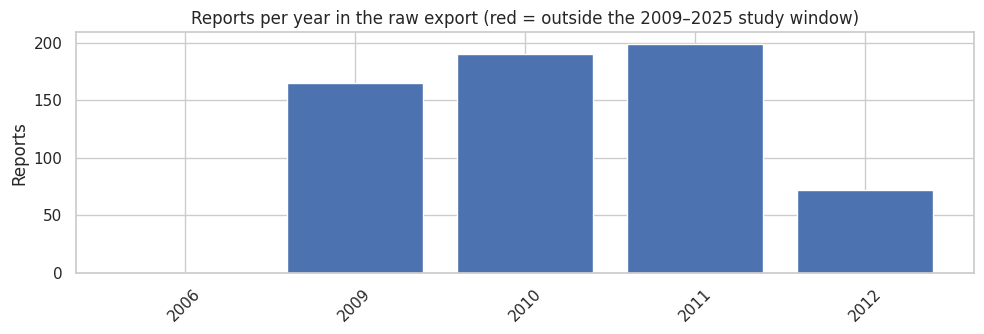

In [17]:
date_str = df["date_raw"].astype("Int64").astype(str)
print("All dates are 6 digits:", date_str.str.fullmatch(r"\d{6}").all(), "| Missing dates:", df["date_raw"].isna().sum())

df["date"] = pd.to_datetime(date_str, format="%Y%m")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
print("Date range:", df["date"].min().strftime("%b %Y"), "to", df["date"].max().strftime("%b %Y"))

year_counts = df["year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
colors = ["#C44E52" if (y < 2009 or y > 2025) else "#4C72B0" for y in year_counts.index]
ax.bar(year_counts.index.astype(str), year_counts.values, color=colors)
ax.set_title("Reports per year in the raw export (red = outside the 2009–2025 study window)")
ax.set_ylabel("Reports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "02_reports_per_year_raw.png"), dpi=150)
plt.show()

In [18]:
START_YEAR, END_YEAR = 2009, 2025
n_before = len(df)
outside_window = df[~df["year"].between(START_YEAR, END_YEAR)]
print("Reports outside the window by year:", outside_window["year"].value_counts().sort_index().to_dict())

df = df[df["year"].between(START_YEAR, END_YEAR)].copy()
print(f"Rows: {n_before} -> {len(df)} (removed {n_before - len(df)})")

Reports outside the window by year: {2006: 1}
Rows: 627 -> 626 (removed 1)


**Decision: keep 2009–2025.** The export covers August 2006 through 2026. The single 2006 report is isolated, with nothing from 2007–2008, and 2026 is a partial year that is still being reported. Including a partial year would make 2026 look like a drop in reporting when the data simply isn't complete yet. Keeping 17 full calendar years makes year-over-year comparisons fair. Removed: **1 report from 2006 and 43 from 2026 (44 total)**, leaving **2,202 reports**.

### 4.3 Checking fatigue inclusion (do all reports really involve fatigue?)
The export came from a fatigue-related search, but I shouldn't assume every row meets that definition. I collect the fatigue evidence available for each report from four places:

| Evidence source | Field |
|---|---|
| Coded human factor, reporter 1 | `Person 1 | Human Factors` contains "Fatigue" |
| Coded human factor, reporter 2 | `Person 2 | Human Factors` contains "Fatigue" |
| Coded event | `Events | Anomaly` contains a fatigue entry (e.g., "Other Fatigue") |
| Reporter's own words | narrative, synopsis or callback explicitly mentions fatigue, being tired, exhaustion, sleep, or drowsiness |

In [19]:
def has_fatigue_code(series):
    return series.fillna("").str.contains("fatigu", case=False)

FATIGUE_TEXT = r"\bfatigu\w*|\btired\b|\bexhausted\b|\bexhaustion\b|\bsleep\w*|\bslept\b|\bdrows\w*"
all_text = (df["narrative_1"].fillna("") + " " + df["narrative_2"].fillna("") + " "
            + df["synopsis"].fillna("") + " " + df["callback_1"].fillna(""))

df["fatigue_hf_p1"] = has_fatigue_code(df["hf_person1"])
df["fatigue_hf_p2"] = has_fatigue_code(df["hf_person2"])
df["fatigue_anomaly"] = has_fatigue_code(df["anomaly_raw"])
df["fatigue_text"] = all_text.str.contains(FATIGUE_TEXT, case=False, regex=True)
df["fatigue_coded"] = df[["fatigue_hf_p1", "fatigue_hf_p2", "fatigue_anomaly"]].any(axis=1)

evidence = (df.groupby(["fatigue_coded", "fatigue_text"]).size()
              .rename("reports").reset_index())
display(evidence)
print("Coded as fatigue in Person 1 or Person 2 Human Factors:",
      (df["fatigue_hf_p1"] | df["fatigue_hf_p2"]).sum(), "of", len(df))

,fatigue_coded,fatigue_text,reports
0,False,False,4
1,False,True,1
2,True,False,131
3,True,True,490


Coded as fatigue in Person 1 or Person 2 Human Factors: 621 of 626


In [20]:
no_code = df[~df["fatigue_coded"]][["acn", "date_raw", "hf_person1", "hf_person2", "fatigue_text", "synopsis"]]
display(no_code)

,acn,date_raw,hf_person1,hf_person2,fatigue_text,synopsis
152,861962,200911,Confusion; Communication Breakdown,Communication Breakdown; Confusion,False,An aircraft swap prior to departure results in the Dispatcher using a different route on the new...
461,961683,201106,Situational Awareness; Communication Breakdown,Communication Breakdown,False,Three mechanics and one Inspector report about their involvement with a horizontal stabilizer ja...
569,991657,201202,Communication Breakdown,Workload; Communication Breakdown,False,Enroute controllers and flight crew describe a conflict event in which an ATC issued crossing re...
609,1006554,201204,Workload; Situational Awareness; Communication Breakdown,Communication Breakdown,True,Flight crew describes an arrival and RNAV 28 approach to a displaced threshold at SBGL. A mis-se...
619,1007796,201204,Situational Awareness; Communication Breakdown,Communication Breakdown; Confusion; Situational Awareness,False,Four mechanics and one Inspector report about their involvement with a First Officer's Forward W...


**What the check found.** All but **13** reports in the study window have fatigue coded by NASA analysts in at least one Human Factors field. Of those 13, **2** reports describe fatigue in the reporter's own words (for example, *"due to fatigue I did not notice the VSI"*) even though it was never coded. The other **11** show no fatigue evidence anywhere. ASRS's search probably matched them on a field that isn't in this export, or on the search logic itself.

**Inclusion rule:** a report is included if fatigue is **coded** (in either reporter's Human Factors or in the Anomaly field) **or** **explicitly described in the report text**. This rule:
- keeps the 2 reports whose narratives clearly describe fatigue (dropping them would discard real fatigue experiences just because of a coding gap);
- excludes the 11 reports with no fatigue evidence, because the research question is specifically about *fatigue-related* reports;
- is written down and saved, so nothing is dropped silently.

> **Your decision point:** If you can recover the exact ASRS search criteria you used (from the Database Online query screen), add them here. If your mentor would rather keep all records exactly as NASA returned them, change `APPLY_FATIGUE_RULE` to `False`. Everything downstream will still run.

In [21]:
APPLY_FATIGUE_RULE = True

df["fatigue_included"] = df["fatigue_coded"] | df["fatigue_text"]
excluded = df[~df["fatigue_included"]][["acn", "date_raw", "hf_person1", "hf_person2", "synopsis"]].copy()
excluded["exclusion_reason"] = "No fatigue code in Human Factors or Anomaly, and no explicit fatigue language in report text"
excluded.to_csv(os.path.join(INTERIM_DIR, "fatigue_exclusion_log.csv"), index=False)

if APPLY_FATIGUE_RULE:
    n_before = len(df)
    df = df[df["fatigue_included"]].copy()
    print(f"Rows: {n_before} -> {len(df)} (excluded {n_before - len(df)}; ACNs saved to fatigue_exclusion_log.csv)")

Rows: 626 -> 622 (excluded 4; ACNs saved to fatigue_exclusion_log.csv)


### 4.4 Standardizing categorical fields
Several categorical fields have many small or inconsistently written categories (e.g., `Other Flight School` vs. `Other Flight school`). Categories with only a handful of reports can't support reliable comparisons, so I group them using standard aviation categories and keep the original raw column next to each new one for traceability.

| New column | How it's built | Why |
|---|---|---|
| `time_of_day` | Placeholder `ZZZ` → missing | `ZZZ` is ASRS's masking code, not a real time |
| `operator` | Air Carrier, Air Taxi, Corporate, Fractional, Personal, FBO; everything else → Other | Categories under ~30 reports are too small to compare |
| `mission` | Passenger, Cargo, Personal, Ferry/Repositioning, Training; the rest → Other | Same reason |
| `far_part` | Part 121 (airlines), Part 135 (charter/commuter), Part 91 (general aviation); the rest → Other | These three regulatory parts cover nearly every report |
| `flight_phase` / `phase_group` | First phase listed; then grouped into Ground, Takeoff & Climb, Cruise, Descent & Approach, Landing | About 5% of reports list several phases. The first is the one the event started in |
| `reporter_role` | Mapped from `Person 1 | Function` | Pilots, controllers, technicians and flight attendants experience fatigue differently |
| `is_uas` | Flags drone (UAS) reports | Only a handful exist; flagged so they can be excluded from comparisons if needed |

In [22]:
for col in df.columns:
    if is_text_column(df[col]):
        df[col] = df[col].str.strip()

df["time_of_day"] = df["time_of_day"].replace("ZZZ", np.nan)

def group_operator(v):
    if pd.isna(v):
        return np.nan
    main = ["Air Carrier", "Air Taxi", "Corporate", "Fractional", "Personal", "FBO"]
    return v if v in main else "Other"

def group_mission(v):
    if pd.isna(v):
        return np.nan
    mapping = {"Passenger": "Passenger", "Cargo / Freight / Delivery": "Cargo",
               "Personal": "Personal", "Ferry / Re-Positioning": "Ferry / Repositioning",
               "Training": "Training"}
    return mapping.get(v, "Other")

def group_far_part(v):
    if pd.isna(v):
        return np.nan
    for part in ["Part 121", "Part 135", "Part 91"]:
        if v == part:
            return part
    return "Other"

PHASE_GROUPS = {
    "Parked": "Ground", "Taxi": "Ground",
    "Takeoff / Launch": "Takeoff & Climb", "Initial Climb": "Takeoff & Climb", "Climb": "Takeoff & Climb",
    "Cruise": "Cruise",
    "Descent": "Descent & Approach", "Initial Approach": "Descent & Approach", "Final Approach": "Descent & Approach",
    "Landing": "Landing",
}

df["operator"] = df["operator_raw"].apply(group_operator)
df["mission"] = df["mission_raw"].apply(group_mission)
df["far_part"] = df["far_part_raw"].apply(group_far_part)
df["flight_phase"] = df["flight_phase_raw"].str.split(";").str[0].str.strip()
df["n_flight_phases"] = df["flight_phase_raw"].str.count(";") + 1
df["phase_group"] = df["flight_phase"].map(PHASE_GROUPS).where(df["flight_phase"].notna())
df.loc[df["flight_phase"].notna() & df["phase_group"].isna(), "phase_group"] = "Other"

print("Reports listing more than one flight phase:", (df["n_flight_phases"] > 1).sum())
for col in ["operator", "mission", "far_part", "phase_group"]:
    print(f"\n{col}:", df[col].value_counts(dropna=False).to_dict())

Reports listing more than one flight phase: 30

operator: {'Air Carrier': 471, 'Other': 62, 'Personal': 27, 'Fractional': 22, 'Corporate': 18, 'Air Taxi': 14, 'FBO': 8}

mission: {'Passenger': 381, 'Other': 146, 'Cargo': 52, 'Personal': 25, 'Training': 9, 'Ferry / Repositioning': 9}

far_part: {'Part 121': 467, 'Part 91': 79, 'Other': 57, 'Part 135': 19}

phase_group: {'Ground': 184, 'Descent & Approach': 162, 'Takeoff & Climb': 89, 'Other': 89, 'Cruise': 70, 'Landing': 28}


In [23]:
ROLE_RULES = [
    ("UAS Operator", ["(UAS)"]),
    ("Flight Attendant", ["Flight Attendant"]),
    ("Air Traffic Control", ["Enroute", "Approach", "Departure", "Local", "Ground", "Handoff / Assist",
                             "Flight Data / Clearance Delivery", "Traffic Management", "Supervisor / CIC"]),
    ("Maintenance", ["Technician", "Inspector", "Quality Assurance"]),
    ("Dispatcher", ["Dispatcher"]),
    ("Pilot", ["Captain", "First Officer", "Pilot Flying", "Pilot Not Flying", "Single Pilot",
               "Relief Pilot", "Instructor", "Check Pilot", "Trainee", "Flight Engineer"]),
]

def map_role(function_text):
    if pd.isna(function_text):
        return np.nan
    parts = [p.strip() for p in function_text.split(";")]
    for role, keys in ROLE_RULES:
        if any(any(k == p or k in p for k in keys) for p in parts):
            return role
    return "Other"

df["reporter_role"] = df["reporter_function"].apply(map_role)
display(pd.crosstab(df["reporter_role"].fillna("Missing"), "reports"))

df["is_uas"] = (df["far_part_raw"].fillna("").str.contains("107|UAS")
                | df["operator_raw"].fillna("").str.contains("UAS")
                | (df["reporter_role"] == "UAS Operator"))
print("Drone (UAS) reports flagged:", df["is_uas"].sum())

col_0,reports
reporter_role,
Air Traffic Control,15
Dispatcher,6
Flight Attendant,26
Maintenance,50
Other,8
Pilot,517


Drone (UAS) reports flagged: 0


**Note on role order.** In `ROLE_RULES`, the more specific roles are checked before *Pilot*. The order matters because function lists can mix roles. For example, a supervisor's function list may include both a controller position and *Supervisor / CIC*, so controller positions are matched before *Pilot*.

### 4.5 Numeric fields hidden inside text
`Person 1 | Experience` stores numbers inside text, e.g. `Flight Crew Last 90 Days 180; Flight Crew Total 15000; Flight Crew Type 5000`. I extract the pilot's **total flight hours** and **hours in the last 90 days**, because experience and recent flying load are plausibly related to fatigue.

In [24]:
def extract_hours(text, label):
    if pd.isna(text):
        return np.nan
    m = re.search(label + r"\s+([\d.]+)", text)
    return float(m.group(1)) if m else np.nan

df["flight_hours_total"] = df["reporter_experience"].apply(lambda t: extract_hours(t, "Flight Crew Total"))
df["flight_hours_90d"] = df["reporter_experience"].apply(lambda t: extract_hours(t, "Flight Crew Last 90 Days"))
df["crew_size"] = pd.to_numeric(df["crew_size"], errors="coerce")

display(df[["flight_hours_total", "flight_hours_90d", "crew_size"]].describe().round(1))

,flight_hours_total,flight_hours_90d,crew_size
count,258.0,263.0,512.0
mean,10666.4,139.7,2.1
std,6655.0,82.2,0.6
min,34.0,1.0,1.0
25%,5500.0,75.0,2.0
50%,10000.0,150.0,2.0
75%,15000.0,200.0,2.0
max,34000.0,600.0,4.0


### 4.6 Splitting multi-value fields into indicator (0/1) columns
Three fields hold lists: **Human Factors**, **Anomaly** and **Contributing Factors**. I split each into one **0/1 indicator column per category** (*multi-hot encoding*), which lets me count, compare and correlate them in EDA.

- **Human factors (`hf_`)**: combined across Person 1 and Person 2, so a factor counts as present if *either* reporter had it coded. This represents what was present in the event, not just in one reporter's account.
- **Anomaly (`anom_`)**: ASRS has more than 70 detailed anomaly codes. I roll them up to their top-level family (e.g., all *"Deviation - Altitude ..."* codes become `altitude_deviation`). The standalone codes `Critical` and `Less Severe` are severity qualifiers rather than event types, so they're dropped from the indicators.
- **Contributing factors (`cf_`)**: used as recorded (17 categories).

In [25]:
def split_multi(value):
    if pd.isna(value):
        return []
    return [p.strip() for p in str(value).split(";") if p.strip()]

def snake(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

ANOMALY_FAMILIES = [
    ("Deviation / Discrepancy - Procedural", "procedural_deviation"),
    ("Deviation - Altitude", "altitude_deviation"),
    ("Deviation - Track / Heading", "track_heading_deviation"),
    ("Deviation - Speed", "speed_deviation"),
    ("Inflight Event / Encounter", "inflight_event"),
    ("Aircraft Equipment Problem", "equipment_problem"),
    ("ATC Issue", "atc_issue"),
    ("Conflict", "conflict"),
    ("Ground Incursion", "ground_incursion_excursion"),
    ("Ground Excursion", "ground_incursion_excursion"),
    ("Ground Event / Encounter", "ground_event"),
    ("Flight Deck / Cabin / Aircraft Event", "flight_deck_cabin_event"),
    ("Airspace Violation", "airspace_violation"),
    ("No Specific Anomaly Occurred", "no_specific_anomaly"),
]

def anomaly_family(code):
    for prefix, fam in ANOMALY_FAMILIES:
        if code.startswith(prefix):
            return fam
    if code in ("Critical", "Less Severe"):
        return None
    return "other"

# Human factors: union of both reporters
hf_lists = [sorted(set(split_multi(a)) | set(split_multi(b))) for a, b in zip(df["hf_person1"], df["hf_person2"])]
# Anomaly families
anom_lists = [sorted({f for f in (anomaly_family(c) for c in split_multi(v)) if f}) for v in df["anomaly_raw"]]
# Contributing factors
cf_lists = [split_multi(v) for v in df["contrib_raw"]]

def multi_hot(lists, prefix, index):
    exploded = pd.Series(lists, index=index).explode().dropna()
    dummies = pd.crosstab(exploded.index, exploded).clip(upper=1)
    dummies.columns = [f"{prefix}{snake(c)}" for c in dummies.columns]
    return dummies.reindex(index, fill_value=0).astype(int)

hf_ind = multi_hot(hf_lists, "hf_", df.index)
anom_ind = multi_hot(anom_lists, "anom_", df.index)
cf_ind = multi_hot(cf_lists, "cf_", df.index)

df = pd.concat([df, hf_ind, anom_ind, cf_ind], axis=1)
df["n_human_factors"] = hf_ind.drop(columns="hf_fatigue", errors="ignore").sum(axis=1)
df["n_anomaly_types"] = anom_ind.sum(axis=1)
df["n_contributing_factors"] = cf_ind.sum(axis=1)

print("Indicator columns created:", hf_ind.shape[1], "human factors |", anom_ind.shape[1],
      "anomaly families |", cf_ind.shape[1], "contributing factors")
display((hf_ind.mean() * 100).round(1).sort_values(ascending=False).rename("% of reports").to_frame())

Indicator columns created: 13 human factors | 14 anomaly families | 17 contributing factors


,% of reports
hf_fatigue,99.8
hf_nan,77.8
hf_situational_awareness,53.4
hf_communication_breakdown,38.3
hf_distraction,32.5
hf_workload,28.5
hf_time_pressure,27.2
hf_confusion,26.0
hf_human_machine_interface,19.0
hf_training_qualification,13.0


**Note on `hf_fatigue`.** Fatigue is coded in almost every report, which is expected since it's the inclusion criterion. Because it barely varies, it carries almost no information as a feature, so it's left out of the `n_human_factors` count. That count tells us how many **other** human factors accompanied fatigue.

### 4.7 Text fields: removing placeholder narratives
A second reporter's narrative (`narrative_2`) sometimes contains only an ASRS placeholder such as *"[Report narrative contained no additional information.]"*. That's an editor's note, not something a reporter wrote, so it's treated as missing.

In [26]:
PLACEHOLDER = r"^\[?\s*(?:report narrative|narrative\s*#?\s*2).{0,30}no additional information"
is_placeholder = df["narrative_2"].fillna("").str.contains(PLACEHOLDER, case=False, regex=True)
print("Placeholder second narratives found:", is_placeholder.sum())
df.loc[is_placeholder, "narrative_2"] = np.nan

df["has_narrative_2"] = df["narrative_2"].notna()
df["text_all"] = df["narrative_1"] + np.where(df["has_narrative_2"], " " + df["narrative_2"].fillna(""), "")
df["narrative_words"] = df["narrative_1"].str.split().str.len()
df["synopsis_words"] = df["synopsis"].str.split().str.len()
print("Reports with a real second narrative:", df["has_narrative_2"].sum(), f"({df['has_narrative_2'].mean():.1%})")

Placeholder second narratives found: 3
Reports with a real second narrative: 619 (99.5%)


**Decision: which text gets analyzed?** The **primary narrative (`narrative_1`)** is the main NLP text. It's present for 100% of reports, so every document comes from the same kind of source: one person's firsthand account. The second narrative exists for under a third of reports. Mixing it in would make those documents longer and give some events two voices. I still keep the combined text in `text_all`, so I can test in the modeling step whether adding it changes the themes.

### 4.8 Missing values
Missing values are handled differently depending on what a blank means:

,% missing
flight_hours_total,58.5
flight_hours_90d,57.7
crew_size,17.7
time_of_day,0.2
flight_conditions,0.0
mission,0.0
operator,0.0
light,0.0
far_part,0.0
reporter_role,0.0


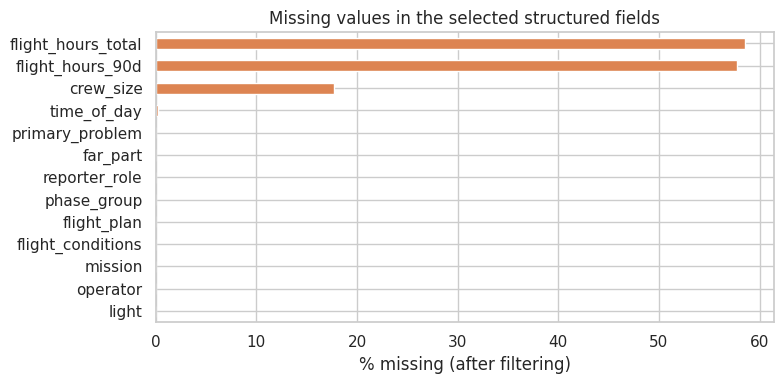

In [27]:
STRUCTURED = ["time_of_day", "flight_conditions", "light", "operator", "mission", "far_part",
              "flight_plan", "phase_group", "reporter_role", "primary_problem",
              "crew_size", "flight_hours_total", "flight_hours_90d"]
missing_table = (df[STRUCTURED].isna().mean() * 100).round(1).sort_values(ascending=False)
display(missing_table.rename("% missing").to_frame())

fig, ax = plt.subplots(figsize=(8, 4))
missing_table.sort_values().plot.barh(ax=ax, color="#DD8452")
ax.set_xlabel("% missing (after filtering)")
ax.set_title("Missing values in the selected structured fields")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "03_missing_selected_fields.png"), dpi=150)
plt.show()

**Decisions on missing values (by type of field):**

| Field type | Fields | Decision | Reasoning |
|---|---|---|---|
| Categorical | time of day, light, flight conditions, operator, mission, FAR Part, flight plan, phase group, reporter role, primary problem | Fill with an explicit **`"Unknown"`** category | In ASRS a blank means *not reported or not applicable* (e.g., light and weather are rarely recorded for ground events). Dropping these rows would throw away up to ~46% of reports, and filling with the most common value would invent information. `"Unknown"` keeps every report and keeps the missingness visible in charts. |
| Numeric | flight hours (total, last 90 days), crew size | **Leave as missing (NaN)**, do not impute | Flight hours exist only for pilots who chose to report them. Controllers and technicians have no flight hours at all. Filling with a median would invent experience that doesn't exist, so analyses of these fields use only reports where the value was given. |
| Indicator (0/1) | `hf_`, `anom_`, `cf_` | Already 0 when not coded | A missing list means nothing was coded, so 0 is accurate. |
| Text | `narrative_1`, `synopsis` | Nothing to fill | 100% complete. |

In [28]:
CATEGORICAL = ["time_of_day", "flight_conditions", "light", "operator", "mission", "far_part",
               "flight_plan", "phase_group", "flight_phase", "reporter_role", "primary_problem"]
for col in CATEGORICAL:
    df[col] = df[col].fillna("Unknown")

print("Remaining missing values in categorical fields:", df[CATEGORICAL].isna().sum().sum())
print("Numeric fields intentionally left with NaN:")
display(df[["crew_size", "flight_hours_total", "flight_hours_90d"]].isna().sum().rename("missing").to_frame())

Remaining missing values in categorical fields: 0
Numeric fields intentionally left with NaN:


,missing
crew_size,110
flight_hours_total,364
flight_hours_90d,359


### 4.9 Outliers
I check the numeric fields for unusual values using the **IQR rule**, which flags values more than 1.5 × IQR above the 75th percentile or below the 25th. The question for each flagged value is whether it's an *error* or a *real but extreme* value.

,n,min,median,max,upper_fence,n_outliers
narrative_words,622.0,15.0,279.5,2086.0,879.6,37.0
synopsis_words,622.0,6.0,33.0,80.0,65.0,9.0
flight_hours_total,258.0,34.0,10000.0,34000.0,29250.0,3.0
flight_hours_90d,263.0,1.0,150.0,600.0,387.5,2.0
crew_size,512.0,1.0,2.0,4.0,2.0,116.0


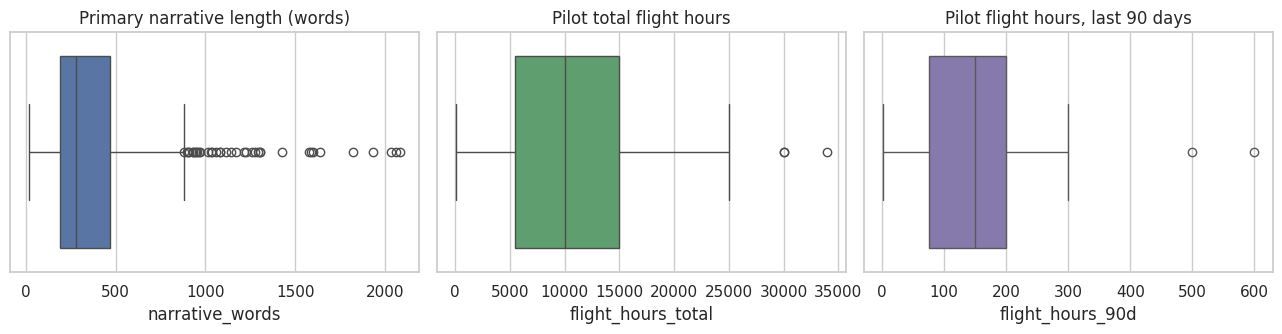

In [29]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"n": len(s), "min": s.min(), "median": s.median(), "max": s.max(),
                      "upper_fence": high, "n_outliers": int(((s < low) | (s > high)).sum())})

NUMERIC = ["narrative_words", "synopsis_words", "flight_hours_total", "flight_hours_90d", "crew_size"]
display(pd.DataFrame({c: iqr_outliers(df[c]) for c in NUMERIC}).T.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
sns.boxplot(x=df["narrative_words"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Primary narrative length (words)")
sns.boxplot(x=df["flight_hours_total"], ax=axes[1], color="#55A868")
axes[1].set_title("Pilot total flight hours")
sns.boxplot(x=df["flight_hours_90d"], ax=axes[2], color="#8172B3")
axes[2].set_title("Pilot flight hours, last 90 days")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "04_outlier_boxplots.png"), dpi=150)
plt.show()

In [30]:
print("Longest narratives (words):", df["narrative_words"].nlargest(5).tolist())
print("Highest total flight hours:", df["flight_hours_total"].nlargest(5).tolist())
display(df.loc[df["flight_hours_90d"] > 300, ["far_part", "operator", "reporter_role", "flight_hours_90d", "flight_hours_total"]]
          .sort_values("flight_hours_90d"))

Longest narratives (words): [2086, 2060, 2036, 1934, 1823]
Highest total flight hours: [34000.0, 30000.0, 30000.0, 25000.0, 25000.0]


,far_part,operator,reporter_role,flight_hours_90d,flight_hours_total
166,Part 121,Air Carrier,Pilot,500.0,20000.0
508,Part 135,Air Taxi,Pilot,600.0,3000.0


**What the outlier check found, and what I decided:**

- **Narrative length: keep.** The IQR rule flags 118 long narratives, up to ~2,200 words. These are real reports from people who wrote detailed accounts, not errors. Length differences are handled in the NLP step, where TF-IDF normalizes each document so long reports don't dominate, and EDA plots length on a log scale.
- **Total flight hours: keep.** The 3 flagged values (30,000–36,000 hours) are realistic for long-career airline captains.
- **Crew size: no action.** Almost every crew has 2 pilots, so the 25th and 75th percentiles are both 2 and the IQR is zero. The IQR rule then flags every 1-, 3- or 4-person crew as an "outlier," which only shows the rule doesn't suit a small, discrete count. Crew sizes of 1–4 are all valid.
- **Hours in the last 90 days: treat impossible values as missing.** U.S. flight-time limits cap Part 121 airline pilots at 100 hours in any 28 days (14 CFR 117.23), which works out to **roughly 320–330 hours in 90 days at most**. Twelve Part 121 reports list 340–800 hours, which these rules don't allow. Two non-airline reports list 600 hours, which would mean flying about 6.7 hours every single day for three months (Part 135 caps unscheduled flying at 500 hours per quarter). The likeliest explanation is that reporters entered *duty* hours or a different time window. Because these values can't be trusted, I **set them to missing** rather than delete the reports, so the reports stay in every other analysis. The original values are kept in `flight_hours_90d_reported`, and the affected rows are flagged with `hours_90d_implausible`.

In [31]:
PART121_CEILING_90D = 330   # 100 h per 28 days (14 CFR 117.23) ≈ 321 h per 90 days, rounded up
OTHER_CEILING_90D = 500     # Part 135 unscheduled ceiling of 500 h per calendar quarter

df["flight_hours_90d_reported"] = df["flight_hours_90d"]
ceiling = np.where(df["far_part"] == "Part 121", PART121_CEILING_90D, OTHER_CEILING_90D)
df["hours_90d_implausible"] = df["flight_hours_90d"] > ceiling
df.loc[df["hours_90d_implausible"], "flight_hours_90d"] = np.nan
print("90-day values set to missing as implausible:", df["hours_90d_implausible"].sum())
print("New maximum 90-day hours:", df["flight_hours_90d"].max())

df["log_narrative_words"] = np.log10(df["narrative_words"])

90-day values set to missing as implausible: 2
New maximum 90-day hours: 300.0


## 5. NLP Text Preparation
The NLP part of this project needs the narratives in a consistent, comparable form. I follow the standard steps for text data: **cleaning → tokenization → stop word removal → lemmatization (compared with stemming) → frequency analysis**.

### 5.1 Features of ASRS narratives that affect cleaning
ASRS narratives have quirks that generic text cleaning won't handle:
- **De-identification placeholders.** Airports, people and companies are masked with codes like `ZZZ`, `ZZZ1`, `X` and `Y`. These are not real words and would show up as falsely "important" terms.
- **Semicolons instead of commas.** ASRS replaces commas with semicolons (e.g., `1;700 FT`).
- **Heavy jargon and abbreviations** (FO, ATC, FMS, MCP). These carry meaning in aviation, so they're **kept** as tokens. The 2-letter minimum token length below is chosen specifically so that short abbreviations like `fo` survive.
- **Numbers** (altitudes, headings, times) are specific to each event and don't describe themes, so they're removed.

In [32]:
print(df["narrative_1"].iloc[0][:700])

Inbound aircraft cabin system pressure 1 inop. Maintenance history reveals chronic write-up. Cell phone used to call Maintenance and Dispatch. Contract Maintenance called and unable to fix and am told non-deferrable. Cell phone used as well as ACARS used to contact crew desk need rooms.  Advised mechanics flying down to repair aircraft. Rescheduled departure for the next day and arrived at airport for preflight planning. Start APU to power aircraft and immediately get 2 ECAMS. 1. Cabin pressure system 1 inop.  2. Yellow hydraulic system resv overheat.  Send system codes to maintenance and advise Dispatch. Mechanics come to aircraft and say they do not know how to fix it because it is a wirin


In [33]:
STOP_WORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

PLACEHOLDER_TOKENS = re.compile(r"\b(z{2,}\w*|x{2,}|y{2,}|[xy]\d*)\b", flags=re.IGNORECASE)

def clean_text(text):
    """Lower-case, remove ASRS masking codes, numbers and punctuation."""
    text = PLACEHOLDER_TOKENS.sub(" ", text)
    text = text.lower().replace(";", " ")
    text = re.sub(r"[^a-z\s]", " ", text)          # drop digits and punctuation
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    return [t for t in clean_text(text).split() if len(t) >= 2]

def remove_stop_words(tokens):
    return [t for t in tokens if t not in STOP_WORDS]

def lemmatize(tokens):
    return [lemmatizer.lemmatize(t) for t in tokens]        # noun lemmatization (see note below)

def stem(tokens):
    return [stemmer.stem(t) for t in tokens]

example = df["narrative_1"].iloc[0][:300]
tok = tokenize(example)
print("ORIGINAL:   ", example)
print("\nTOKENS:     ", tok[:25])
print("\nNO STOPS:   ", remove_stop_words(tok)[:25])
print("\nLEMMATIZED: ", lemmatize(remove_stop_words(tok))[:25])
print("\nSTEMMED:    ", stem(remove_stop_words(tok))[:25])

ORIGINAL:    Inbound aircraft cabin system pressure 1 inop. Maintenance history reveals chronic write-up. Cell phone used to call Maintenance and Dispatch. Contract Maintenance called and unable to fix and am told non-deferrable. Cell phone used as well as ACARS used to contact crew desk need rooms.  Advised mec

TOKENS:      ['inbound', 'aircraft', 'cabin', 'system', 'pressure', 'inop', 'maintenance', 'history', 'reveals', 'chronic', 'write', 'up', 'cell', 'phone', 'used', 'to', 'call', 'maintenance', 'and', 'dispatch', 'contract', 'maintenance', 'called', 'and', 'unable']

NO STOPS:    ['inbound', 'aircraft', 'cabin', 'system', 'pressure', 'inop', 'maintenance', 'history', 'reveals', 'chronic', 'write', 'cell', 'phone', 'used', 'call', 'maintenance', 'dispatch', 'contract', 'maintenance', 'called', 'unable', 'fix', 'told', 'non', 'deferrable']

LEMMATIZED:  ['inbound', 'aircraft', 'cabin', 'system', 'pressure', 'inop', 'maintenance', 'history', 'reveals', 'chronic', 'write', 'cell', 

**Why lemmatize as nouns only?** WordNet's lemmatizer treats every word as a noun by default. That turns plurals into singulars (*pilots → pilot*, *flights → flight*, *hours → hour*) but leaves verb forms alone. I tested also lemmatizing verbs (`pos="v"`) and decided against it. In aviation, many key terms are *-ing* words used as nouns (*landing, taxiing, flying, briefing, scheduling*), and verb lemmatization would turn *landing* into *land* and *pilot flying* into *pilot fly*, which makes topics harder to read. Lemmatizing nouns only is a deliberate trade-off that keeps aviation phrases intact.

### 5.2 Apply the pipeline to every narrative

In [34]:
df["tokens"] = df["narrative_1"].apply(tokenize)
df["tokens_nostop"] = df["tokens"].apply(remove_stop_words)
df["tokens_lemma"] = df["tokens_nostop"].apply(lemmatize)
df["tokens_stem"] = df["tokens_nostop"].apply(stem)

df["text_lemma"] = df["tokens_lemma"].str.join(" ")
df["text_stem"] = df["tokens_stem"].str.join(" ")
df["clean_token_count"] = df["tokens_lemma"].str.len()

vocab = pd.Series({
    "raw tokens (after cleaning)": len(set(t for ts in df["tokens"] for t in ts)),
    "after stop word removal": len(set(t for ts in df["tokens_nostop"] for t in ts)),
    "after lemmatization": len(set(t for ts in df["tokens_lemma"] for t in ts)),
    "after stemming": len(set(t for ts in df["tokens_stem"] for t in ts)),
}, name="unique words (vocabulary size)")
display(vocab.to_frame())
print("Total tokens before stop word removal:", df["tokens"].str.len().sum())
print("Total tokens after stop word removal: ", df["tokens_nostop"].str.len().sum())

,unique words (vocabulary size)
raw tokens (after cleaning),8418
after stop word removal,8282
after lemmatization,7478
after stemming,5287


Total tokens before stop word removal: 216078
Total tokens after stop word removal:  114891


**Decision: lemmatization over stemming.** Both shrink the vocabulary, and stemming shrinks it more. But stemming produces fragments that aren't real words, so topics would be labeled with stems like *"fatigu"*, *"experi"* and *"pressur"* instead of words people can read. Topics are judged by humans reading the top words, so **interpretability matters more than a slightly smaller vocabulary**. The lemmatized text (`text_lemma`) goes forward to EDA and modeling. The stemmed version is saved only for comparison.

### 5.3 First frequency analysis

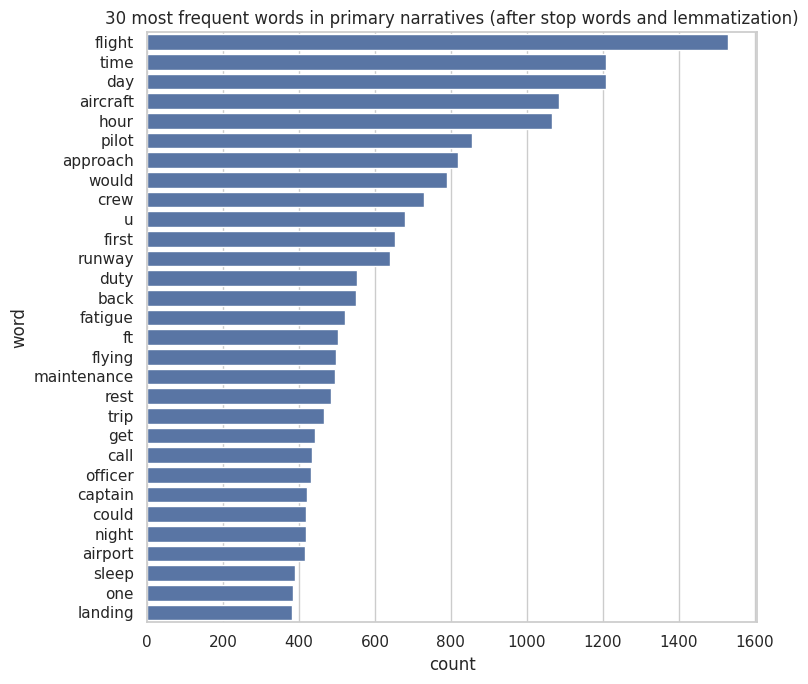

In [35]:
word_freq = Counter(t for ts in df["tokens_lemma"] for t in ts)
top_words = pd.DataFrame(word_freq.most_common(30), columns=["word", "count"])

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=top_words, y="word", x="count", ax=ax, color="#4C72B0")
ax.set_title("30 most frequent words in primary narratives (after stop words and lemmatization)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "05_top_words.png"), dpi=150)
plt.show()

**What the frequency analysis shows.** The most frequent words are general vocabulary that appears in most reports (*flight, aircraft, time, day, hour*), plus filler words that NLTK's stop list doesn't cover (*would, us*). They describe the setting, not the theme, so they would crowd out meaningful topics. They are **candidates for a domain-specific stop word list**. I'll decide that list in EDA by checking what share of documents each word appears in, rather than removing words by guesswork here.

## 6. Save the cleaned dataset

In [36]:
FINAL_COLUMNS = (
    ["acn", "date", "year", "month", "time_of_day", "light", "flight_conditions",
     "operator", "operator_raw", "mission", "mission_raw", "far_part", "far_part_raw", "flight_plan",
     "aircraft_model", "crew_size", "flight_phase", "phase_group", "n_flight_phases",
     "reporter_role", "reporter_org", "flight_hours_total", "flight_hours_90d", "flight_hours_90d_reported",
     "hours_90d_implausible", "is_uas",
     "primary_problem", "fatigue_hf_p1", "fatigue_hf_p2", "fatigue_anomaly", "fatigue_text",
     "n_human_factors", "n_anomaly_types", "n_contributing_factors"]
    + list(hf_ind.columns) + list(anom_ind.columns) + list(cf_ind.columns)
    + ["hf_person1", "hf_person2", "anomaly_raw", "contrib_raw",
       "narrative_1", "narrative_2", "has_narrative_2", "synopsis", "text_all",
       "narrative_words", "log_narrative_words", "synopsis_words", "clean_token_count",
       "text_lemma", "text_stem"]
)
clean = df[FINAL_COLUMNS].reset_index(drop=True)

assert clean["acn"].is_unique
assert clean["year"].between(START_YEAR, END_YEAR).all()

out_path = os.path.join(PROCESSED_DIR, "asrs_fatigue_clean.csv")
clean.to_csv(out_path, index=False)
data_dict_clean = build_data_dictionary(clean)
data_dict_clean.to_csv(os.path.join(INTERIM_DIR, "data_dictionary_clean.csv"), index=False)

print("Saved:", out_path)
print("Final shape:", clean.shape)

Saved: data/processed/asrs_fatigue_clean.csv
Final shape: (622, 93)


### Record of every row removed

In [37]:
flow = pd.DataFrame({
    "step": ["Raw ASRS export", "After 2009–2025 date filter", "After fatigue inclusion rule"],
    "reports": [len(raw), len(raw) - len(outside_window), len(clean)],
})
flow["removed_at_step"] = (-flow["reports"].diff()).fillna(0).astype(int)
display(flow)

,step,reports,removed_at_step
0,Raw ASRS export,627,0
1,After 2009–2025 date filter,626,1
2,After fatigue inclusion rule,622,4


## 7. Summary of Data Wrangling

**Collection.** I loaded the NASA ASRS export (2,246 reports × 126 columns), handled its two-row header by combining group and field names into unique column names, and kept the raw data untouched.

**Organization.** I set up a reproducible folder structure (raw / interim / processed / figures) and saved every log and dictionary.

**Definition.** I built a full data dictionary (`data/interim/data_dictionary_raw.csv`), found that missingness is concentrated in *not applicable* field groups (Aircraft 2, UAS, maintenance), and kept 24 of the 126 columns using documented rules (`column_selection_log.csv`).

**Cleaning.**
- **Duplicates:** none found by report ID, by full row, or by narrative. The one shared synopsis belongs to two different events, so both were kept.
- **Date window:** parsed YYYYMM dates and limited the data to 2009–2025, removing 44 reports (1 isolated 2006 report and 43 from the incomplete 2026).
- **Fatigue inclusion:** verified that fatigue is coded or explicitly described in every retained report. 2 uncoded reports were kept because their narratives describe fatigue, and 11 with no fatigue evidence were excluded and logged (`fatigue_exclusion_log.csv`). **Final sample: 2,191 reports.**
- **Categories:** grouped small and inconsistent categories for operator, mission, FAR Part, flight phase and reporter role, keeping the raw versions.
- **Multi-value fields:** split Human Factors, Anomaly and Contributing Factors into 0/1 indicator columns.
- **Missing values:** categorical blanks became an explicit `"Unknown"` because blank means *not reported* in ASRS. Numeric experience fields stay NaN because imputing them would invent data.
- **Outliers:** long narratives and high career hours are real and were kept. 14 last-90-day flight-hour values above what U.S. flight-time limits allow were set to missing (originals preserved and flagged), so the reports themselves stay in the data.

**NLP preparation.** I removed ASRS masking codes, numbers and punctuation, tokenized, removed English stop words, and lemmatized (chosen over stemming for readable topics). An initial frequency analysis found generic aviation words that EDA will evaluate as domain stop words.

**Output:** `data/processed/asrs_fatigue_clean.csv`, the input to the EDA notebook.